# Data: loading, exclusions, descriptive plots

**This notebook does the following**
1. Loads the open dataset from Brands et al. (2024).
2. Applies the exclusion criteria for reaction times.
3. Saves a cleaned file.
4. Draws descriptive plots. 

FYI **basic** = trial without a cue, **cued** = trial with a personal cue (future or past event), **later** = choosing the larger, delayed reward.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- paths -------------------------------------------------------------
DATA_PATH = Path(os.environ.get(
    "DD_RAWDATA",
    "../data/raw/dd_rawdata.txt"))
OUT_DIR = Path("../data/derived"); OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("../figures");      FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- exclusion rules (fixed before any modelling) ----------------------
RT_MIN = 0.25   # seconds: faster than this is not a real decision
RT_MAX = 10.0   # seconds: slower than this looks like they stopped doing the task
SLOW_PERSON = 25  # much slower than everyone else; kept, but flagged for sensitivity checks

# --- plot style ---------------------------------------------------------
COL = {"basic": "#8a8984", "future": "#2a78d6", "past": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2,
})
def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png"); plt.show()

## 1. Load dataset

In [2]:
raw = pd.read_csv(DATA_PATH, sep=" ", quotechar='"', index_col=0)
raw = raw.rename(columns={"sub_id": "person", "sess_id": "session", "ll_reward": "later_amount", "ss_reward": "now_amount"})
raw["condition"] = raw["cond"].map({"N": "basic", "F": "future", "P": "past"})
raw["cued"] = (raw["condition"] != "basic").astype(int)
# position of the trial within its session (file order = order shown)
raw["trial_in_session"] = raw.groupby(["person", "session"]).cumcount() + 1

print(f"{len(raw):,} trials · {raw.person.nunique()} people · {raw.session.nunique()} sessions")
print("missing values:", int(raw.isna().sum().sum()))
raw.head()

16,128 trials · 42 people · 2 sessions
missing values: 0


,trial,now_amount,later_amount,delay,choice,rt,cond,person,session,condition,cued,trial_in_session
1,1,20,21.0,2,1,14.294940,F,1,1,future,1,1
2,2,20,40.0,85,0,7.345293,N,1,1,basic,0,2
3,3,20,80.0,81,1,13.796072,F,1,1,future,1,3
4,4,20,45.0,2,1,4.073228,F,1,1,future,1,4
5,5,20,69.0,81,1,11.556674,F,1,1,future,1,5


## 2. Check the design
Every person should have 96 basic and 96 cued trials per session, with a future cue on one day and a past cue on the other.

In [3]:
design = raw.groupby(["person", "session", "condition"]).size().unstack(fill_value=0)
assert (design["basic"] == 96).all() and ((design["future"] + design["past"]) == 96).all()
order = (raw[raw.cued == 1].groupby(["person", "session"]).condition.first().unstack()
         .rename(columns={1: "day 1 cue", 2: "day 2 cue"}))
print("Cue order across people:"); print(order.value_counts().to_string())
print("\nLater amounts per condition and session:", raw.groupby(["person","session","condition"]).later_amount.nunique().unique())
print("Delays per condition and session:      ", raw.groupby(["person","session","condition"]).delay.nunique().unique())

Cue order across people:
day 1 cue  day 2 cue
future     past         21
past       future       21

Later amounts per condition and session: [16]
Delays per condition and session:       [6 5]


## 3. Response times before exclusions
The horizontal axis is on a log scale so both very fast and very slow responses are visible.

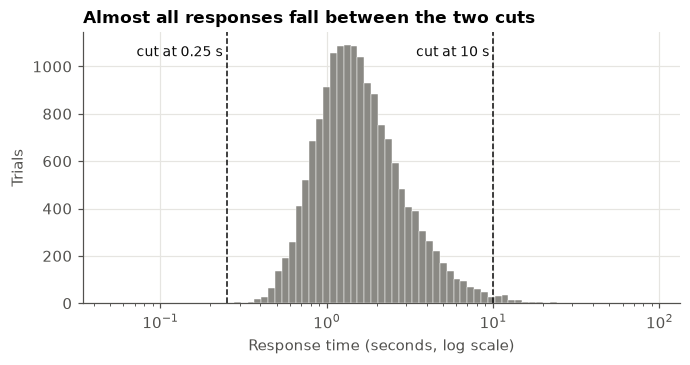

Faster than 0.25 s: 9 trials from 3 people
Slower than 10 s: 124 trials from 23 people (longest 83 s)
Slower than 10 s (kept): 124 trials, 47 of them from person 25


In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.logspace(np.log10(0.05), np.log10(raw.rt.max()*1.1), 80)
ax.hist(raw.rt.clip(lower=0.05), bins=bins, color=COL["basic"], edgecolor="white", linewidth=0.3)
for x, lab in [(RT_MIN, f"{RT_MIN} s"), (RT_MAX, f"{RT_MAX:.0f} s")]:
    ax.axvline(x, color=INK, lw=1, ls="--"); ax.text(x, ax.get_ylim()[1]*0.95, f"cut at {lab} ", color=INK, va="top", ha="right", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("Response time (seconds, log scale)"); ax.set_ylabel("Trials")
ax.set_title("Almost all responses fall between the two cuts")
save(fig, "01_rt_distribution")

too_fast, too_slow = raw.rt < RT_MIN, raw.rt > RT_MAX
print(f"Faster than {RT_MIN} s: {too_fast.sum()} trials from {raw[too_fast].person.nunique()} people")
print(f"Slower than {RT_MAX:.0f} s: {too_slow.sum()} trials from {raw[too_slow].person.nunique()} people (longest {raw.rt.max():.0f} s)")
print(f"Slower than 10 s (kept): {(raw.rt > 10).sum()} trials, {(raw[raw.rt > 10].person == SLOW_PERSON).sum()} of them from person {SLOW_PERSON}")

## 4. Apply exclusions and save cleaned dataset
Excluded trials stay in the file, marked `keep = 0`, so the order of trials in each session is preserved. Later notebooks need that order for the attention model.

In [5]:
df = raw.copy()
df["keep"] = (~(too_fast | too_slow)).astype(int)
df["slow_person"] = (df.person == SLOW_PERSON).astype(int)
cols = ["person", "session", "trial_in_session", "condition", "cued", "now_amount", "later_amount", "delay", "choice", "rt", "keep", "slow_person"]
df = df[cols]
df.to_csv(OUT_DIR / "trials_clean.csv", index=False)
print(f"Kept {df.keep.sum():,} of {len(df):,} trials ({1 - df.keep.mean():.2%} excluded). Saved to {OUT_DIR / 'trials_clean.csv'}")
d = df[df.keep == 1].copy()   # used for everything below

Kept 15,995 of 16,128 trials (0.82% excluded). Saved to ../data/derived/trials_clean.csv


## 5. Does the cue change choices?
Each thin line is one person in one session, going from their basic trials to their cued trials on the same day.

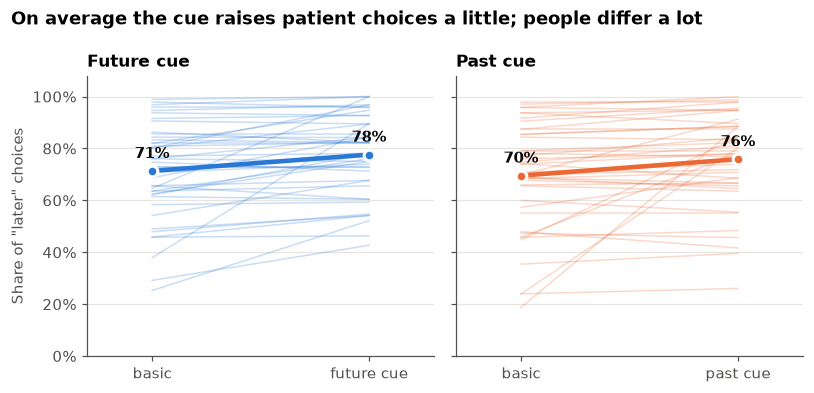

In [6]:
share = d.groupby(["person", "session", "condition"]).choice.mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6), sharey=True)
for ax, cue in zip(axes, ["future", "past"]):
    s = share.dropna(subset=[cue])
    for _, r in s.iterrows():
        ax.plot([0, 1], [r["basic"], r[cue]], color=COL[cue], alpha=0.25, lw=1)
    ax.plot([0, 1], [s["basic"].mean(), s[cue].mean()], color=COL[cue], lw=3, marker="o", ms=7, markeredgecolor="white", markeredgewidth=2)
    for x, v in [(0, s["basic"].mean()), (1, s[cue].mean())]:
        ax.text(x, v + 0.05, f"{v:.0%}", ha="center", color=INK, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["basic", f"{cue} cue"]); ax.set_xlim(-0.3, 1.3); ax.set_ylim(0, 1.08)
    ax.set_title(f"{cue.capitalize()} cue"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel('Share of "later" choices'); axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fig.suptitle("On average the cue raises patient choices a little; people differ a lot", x=0.02, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "01_cue_effect_choices")

## 6. Who responds to the cue?
Each person's cue effect is their share of "later" choices on cued trials minus basic trials on the same day. If responding to cues is a stable trait, people who respond to the future cue should also respond to the past cue, which was tested on a different day.

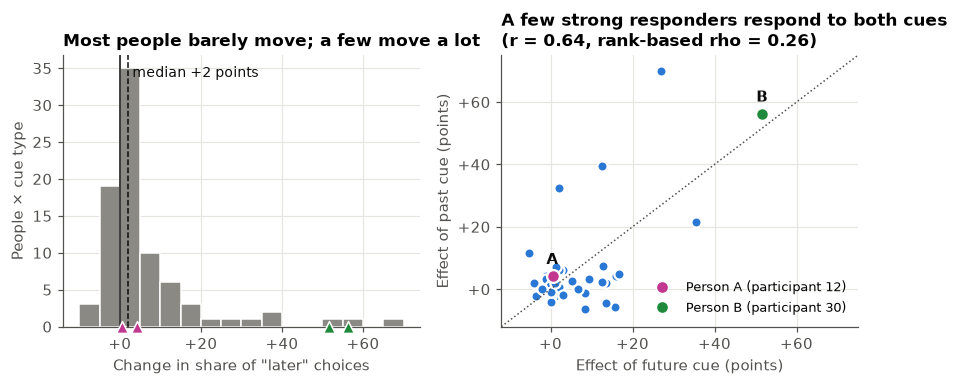

Pearson r = 0.64 · Spearman rho = 0.26 (the rank-based value is the safer one to quote)


,future,past
count,42.000,42.000
mean,0.063,0.063
std,0.111,0.156
min,-0.052,-0.062
25%,0.000,-0.010
50%,0.018,0.021
75%,0.117,0.048
max,0.517,0.698


In [7]:
eff = pd.DataFrame({cue: (share[cue] - share["basic"]).dropna().groupby("person").first() for cue in ["future", "past"]})
r = eff.corr().iloc[0, 1]
rho = eff.corr(method="spearman").iloc[0, 1]   # rank-based: not driven by the few big responders
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
ax = axes[0]
both = pd.concat([eff.future, eff.past])
ax.hist(both, bins=np.arange(-0.10, 0.75, 0.05), color=COL["basic"], edgecolor="white")
ax.axvline(0, color=INK, lw=1); ax.axvline(both.median(), color=INK, lw=1, ls="--")
ax.text(both.median() + 0.01, ax.get_ylim()[1]*0.92, f"median +{both.median()*100:.0f} points", fontsize=9, color=INK)
ax.set_xlabel('Change in share of "later" choices'); ax.set_ylabel("People × cue type"); ax.set_title("Most people barely move; a few move a lot")
ax.xaxis.set_major_formatter(lambda v, _: f"{v*100:+.0f}")
ax = axes[1]
ax.scatter(eff.future, eff.past, s=45, color=COL["future"], edgecolor="white", linewidth=1.5)
lim = [-0.12, 0.75]; ax.plot(lim, lim, color=MUTED, lw=1, ls=":"); ax.set_xlim(lim); ax.set_ylim(lim)
import sys; sys.path.insert(0, "../src"); import highlight as hl
hl.mark(ax, {l: (eff.future[p], eff.past[p]) for l, p in hl.present(eff.index).items()}, size=70)
for l, p in hl.present(eff.index).items():                     # the histogram: a small triangle under each of their two values
    axes[0].scatter([eff.future[p], eff.past[p]], [0, 0], marker="^", s=60, color=hl.COLOR[l], edgecolor="white", zorder=6, clip_on=False)
ax.legend(handles=hl.handles(), loc="lower right", fontsize=8.5)
ax.set_xlabel("Effect of future cue (points)"); ax.set_ylabel("Effect of past cue (points)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v*100:+.0f}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v*100:+.0f}")
ax.set_title(f"A few strong responders respond to both cues\n(r = {r:.2f}, rank-based rho = {rho:.2f})")
fig.tight_layout(); save(fig, "01_who_responds")
print(f"Pearson r = {r:.2f} · Spearman rho = {rho:.2f} (the rank-based value is the safer one to quote)")
eff.describe().round(3)

## 7. Choices by offer
The task has 16 sizes of later reward and 6 delays per person (ranked shortest to longest). These are the built-in levels used later to compare simulated and real choices.

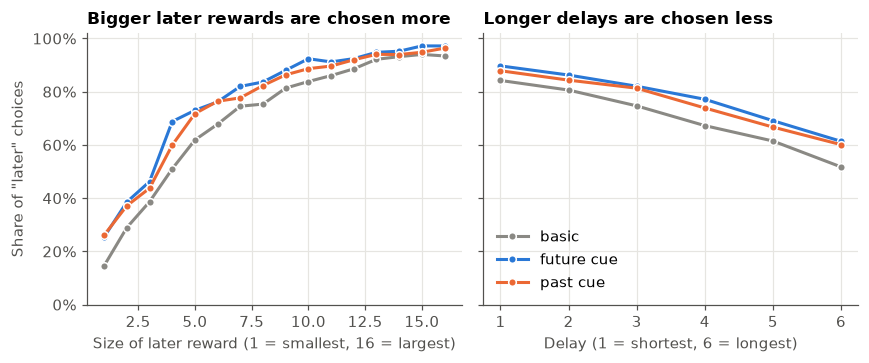

In [8]:
d["amount_level"] = d.groupby(["person", "session", "condition"]).later_amount.rank(method="dense").astype(int)
d["delay_level"]  = d.groupby(["person", "session", "condition"]).delay.rank(method="dense").astype(int)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4), sharey=True)
for ax, lev, xl in zip(axes, ["amount_level", "delay_level"], ["Size of later reward (1 = smallest, 16 = largest)", "Delay (1 = shortest, 6 = longest)"]):
    for cond in ["basic", "future", "past"]:
        m = d[d.condition == cond].groupby(lev).choice.mean()
        ax.plot(m.index, m.values, color=COL[cond], marker="o", ms=5, markeredgecolor="white", label=cond if cond == "basic" else f"{cond} cue")
    ax.set_xlabel(xl); ax.set_ylim(0, 1.02)
axes[0].set_ylabel('Share of "later" choices'); axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].set_title("Bigger later rewards are chosen more"); axes[1].set_title("Longer delays are chosen less")
axes[1].legend(loc="lower left")
fig.tight_layout(); save(fig, "01_choice_curves")

## 8. How behaviour changes within a session
Each session is cut into 8 blocks of 24 trials.

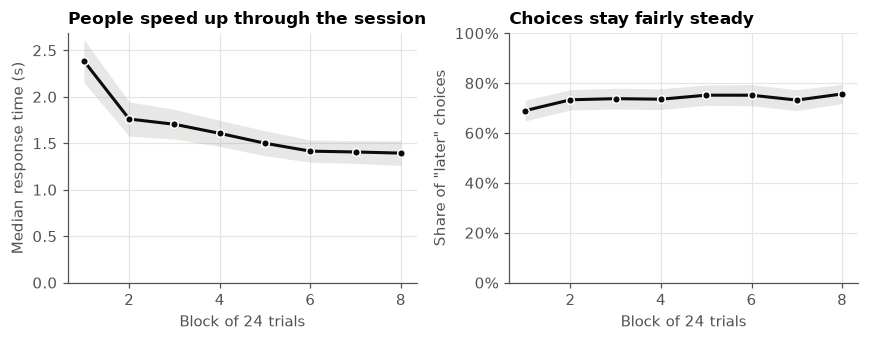

In [9]:
d["block"] = (d.trial_in_session - 1) // 24 + 1
per = d.groupby(["person", "session", "block"]).agg(rt=("rt", "median"), later=("choice", "mean")).groupby("block")
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, col, yl, tt in zip(axes, ["rt", "later"], ["Median response time (s)", 'Share of "later" choices'],
                           ["People speed up through the session", "Choices stay fairly steady"]):
    m, se = per[col].mean(), per[col].sem()
    ax.fill_between(m.index, m - 1.96*se, m + 1.96*se, color=COL["basic"], alpha=0.2, lw=0)
    ax.plot(m.index, m.values, color=INK, marker="o", ms=5, markeredgecolor="white")
    ax.set_xlabel("Block of 24 trials"); ax.set_ylabel(yl); ax.set_title(tt)
axes[0].set_ylim(0, None); axes[1].set_ylim(0, 1); axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fig.tight_layout(); save(fig, "01_session_time_course")

## 9. How consistent are people from day 1 to day 2?
Using basic trials only to estimate the human ceiling. This is important bc a simulated user cannot match a person better than that person matches themselves.

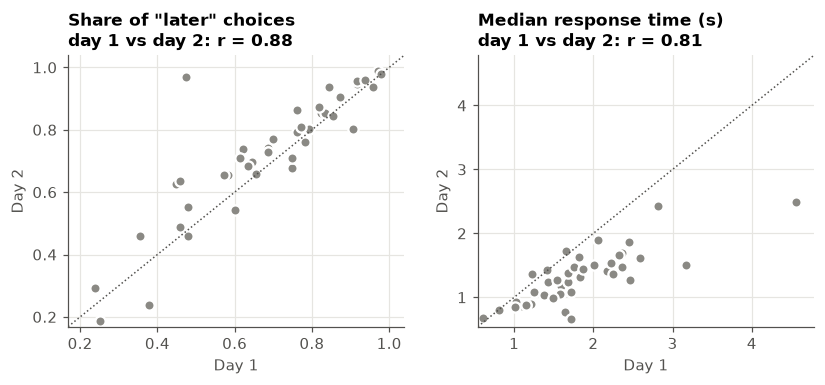

In [10]:
b = d[d.condition == "basic"].groupby(["person", "session"]).agg(later=("choice", "mean"), rt=("rt", "median")).unstack()
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.6))
for ax, col, lab, fmt in zip(axes, ["later", "rt"], ['Share of "later" choices', "Median response time (s)"], ["{:.0%}", "{:.1f}"]):
    x, y = b[col][1], b[col][2]; r = np.corrcoef(x, y)[0, 1]
    ax.scatter(x, y, s=45, color=COL["basic"], edgecolor="white", linewidth=1.5)
    lo, hi = min(x.min(), y.min())*0.9, max(x.max(), y.max())*1.05
    ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1, ls=":"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("Day 1"); ax.set_ylabel("Day 2"); ax.set_title(f"{lab}\nday 1 vs day 2: r = {r:.2f}")
fig.tight_layout(); save(fig, "01_day1_day2_consistency")

## Summary
- The clean file is saved in `data/derived/trials_clean.csv`. Excluded trials are marked, not removed.
- The cue raises patient choices slightly on average, with large differences between people.
- A few people respond strongly to both cues. Across the whole group the link between the two cue effects is weak once those few are discounted (rank-based correlation), so responsiveness may be a trait of a minority, not a smooth scale.
- People speed up within a session, which the models need to handle.
- People are consistent across days, which sets the ceiling for any simulated user.